In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import json
import os
from sklearn.metrics import r2_score


In [4]:
os.makedirs("results", exist_ok=True)

In [5]:
G = 9.81

In [6]:
TRAIN_FILE = "training.csv"
TEST_FILE = "testing.csv"

In [7]:

AXES = [
    "Acceleration x (m/s^2)",
    "Acceleration y (m/s^2)",
    "Acceleration z (m/s^2)"
]


In [8]:
POSES = {
    "+X": [G, 0, 0],
    "-X": [-G, 0, 0],
    "+Y": [0, G, 0],
    "-Y": [0, -G, 0],
    "+Z": [0, 0, G],
    "-Z": [0, 0, -G]
}

In [9]:
training = pd.read_csv("training.csv")
testing = pd.read_csv("testing.csv")

In [10]:
training.shape

(86323, 10)

In [11]:
testing.shape

(86124, 10)

In [12]:
print(training.columns.tolist())

['Time (s)', 'Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)', 'source_row', 'segment_id', 'pose_observed', 'repeat', 'split']


In [13]:
print(testing.columns.tolist())

['Time (s)', 'Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)', 'source_row', 'segment_id', 'pose_observed', 'repeat', 'split']


In [14]:
required_columns = AXES + ["pose_observed"]

In [15]:
for column in required_columns:
    if column not in training.columns:
        raise ValueError(
            f"Training file is missing column: {column}"
        )

In [16]:
    if column not in testing.columns:
        raise ValueError(
            f"Testing file is missing column: {column}"
        )

In [17]:
training["pose_observed"] = (
    training["pose_observed"].astype(str).str.strip()
)

testing["pose_observed"] = (
    testing["pose_observed"].astype(str).str.strip()
)

In [18]:
training = training[
    training["pose_observed"].isin(POSES)
].copy()

testing = testing[
    testing["pose_observed"].isin(POSES)
].copy()


In [19]:
if training.empty or testing.empty:
    raise ValueError(
        "No recognised pose labels found Check the pose_observed column."
      
    )

In [20]:
train_means = training.groupby(
    "pose_observed"
)[AXES].mean()


In [21]:
available_poses = [
    pose for pose in POSES
    if pose in train_means.index
]


In [22]:
if len(available_poses) < 6:
    raise ValueError(
        "At least four suitable orientations are needed "
        "to estimate the full 3D calibration model."
    )

In [23]:
# X contains the expected gravity vectors.
X_train = np.array([
    POSES[pose] for pose in available_poses
], dtype=float)

# y contains the measured accelerometer values.
y_train = np.array([
    train_means.loc[pose, AXES].to_numpy(dtype=float)
    for pose in available_poses
])


In [24]:
model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression model trained!")


Linear Regression model trained!


In [25]:
S = model.coef_
b = model.intercept_

print("\nCalibration matrix S:")
print(S)

print("\nSensor bias b:")
print(b)


Calibration matrix S:
[[ 0.9995644  -0.00806265  0.01570527]
 [ 0.0055988   0.99787034  0.00344103]
 [-0.00315122  0.00589753  0.99844564]]

Sensor bias b:
[-0.0507473   0.06856443  0.10433953]


In [28]:
def means_per_pose(df, axes=AXES, pose_col="pose_observed"):
    """Per-pose mean of the static rows (no rest detector yet — temporary)."""
    return df.groupby(pose_col)[axes].mean()

In [29]:
##accuracy = model.score(X_train, y_train)

##print("R² score:", accuracy)
# ---------- training R² (self-consistent, NOT the headline) ----------
r2_train = model.score(X_train, y_train)
print(f"R² (train, session 1): {r2_train:.6f}   "
      f"<- self-consistent, not evidence")

# ---------- held-out R² (the number the report quotes) ----------
if "test_means" not in globals():
    test_means = means_per_pose(testing)

test_poses = [p for p in POSES if p in test_means.index]
X_test = np.array([POSES[p] for p in test_poses], dtype=float)
y_test = np.array(
    [test_means.loc[p, AXES].to_numpy(dtype=float)
     for p in test_poses]
)

r2_test = model.score(X_test, y_test)
print(f"R² (test,  session 2): {r2_test:.6f}   "
      f"<- held-out evidence")
print(f"Drop:                  {r2_train - r2_test:+.6f}")

R² (train, session 1): 0.999890   <- self-consistent, not evidence
R² (test,  session 2): 0.999873   <- held-out evidence
Drop:                  +0.000017


In [30]:
def sig(row):
    return tuple(round(row[AXES[k]], 3) for k in range(3))

train_sig = set(training.apply(sig, axis=1))
test_sig  = set(testing.apply(sig, axis=1))
print("overlap fraction:", len(train_sig & test_sig) / len(test_sig))

overlap fraction: 0.6553866274317476


In [90]:
def calibrate(measured_values):
    """
    Convert measured accelerations into calibrated
    estimates of the true acceleration vector.
    """

    measured_values = np.asarray(
        measured_values, dtype=float
    )

    return np.linalg.solve(
        S,
        (measured_values - b).T
    ).T


In [91]:
def angle_error(estimated, expected):
    """Calculate the angle between two vectors."""

    estimated_norm = np.linalg.norm(
        estimated, axis=1
    )

    expected_norm = np.linalg.norm(
        expected, axis=1
    )

    denominator = np.maximum(
        estimated_norm * expected_norm, 1e-12
    )

    cosine = np.sum(
        estimated * expected, axis=1
    ) / denominator

    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

In [92]:
test_means = testing.groupby(
    "pose_observed"
)[AXES].mean()

results = []

for pose, expected_vector in POSES.items():

    if pose not in test_means.index:
        continue

    measured = test_means.loc[
        pose, AXES
    ].to_numpy(dtype=float).reshape(1, 3)

    expected = np.array(
        expected_vector, dtype=float
    ).reshape(1, 3)

    corrected = calibrate(measured)

    error_before = np.linalg.norm(
        measured - expected
    )

    error_after = np.linalg.norm(
        corrected - expected
    )

    angle_before = angle_error(
        measured, expected
    )[0]

    angle_after = angle_error(
        corrected, expected
    )[0]

    results.append({
        "pose": pose,
        "error_before_m_s2": error_before,
        "error_after_m_s2": error_after,
        "angle_before_degrees": angle_before,
        "angle_after_degrees": angle_after
    })

In [93]:
results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError(
        "No recognised orientations found in testing data."
    )


In [94]:
print(results_df.round(4).to_string(index=False))

pose  error_before_m_s2  error_after_m_s2  angle_before_degrees  angle_after_degrees
  +X             0.1724            0.0639                0.7505               0.0973
  -X             0.1681            0.0651                0.7377               0.0981
  +Y             0.3341            0.1329                1.9474               0.7489
  -Y             0.1140            0.0876                0.5919               0.4643
  +Z             0.2784            0.1408                1.5929               0.7906
  -Z             0.1399            0.1434                0.6887               0.7955


In [95]:
print("\nMean error before calibration:",
      round(results_df[
          "error_before_m_s2"
      ].mean(), 4), "m/s^2")



Mean error before calibration: 0.2012 m/s^2


In [96]:
print("Mean error after calibration:",
      round(results_df[
          "error_after_m_s2"
      ].mean(), 4), "m/s^2")


Mean error after calibration: 0.1056 m/s^2


In [97]:
print("\nMean angle error before calibration:",
      round(results_df[
          "angle_before_degrees"
      ].mean(), 4), "degrees")



Mean angle error before calibration: 1.0515 degrees


In [98]:
print("Mean angle error after calibration:",
      round(results_df[
          "angle_after_degrees"
      ].mean(), 4), "degrees")


Mean angle error after calibration: 0.4991 degrees


In [101]:
design_matrix = np.column_stack([
    X_train,
    np.ones(len(X_train))
])


In [102]:
rank = np.linalg.matrix_rank(design_matrix)
condition_number = np.linalg.cond(design_matrix)

In [103]:
print("Design matrix rank:", rank)
print("Condition number:", condition_number)


Design matrix rank: 4
Condition number: 5.66380614075023


In [104]:
results_df.to_csv(
    "results/testing_results.csv",
    index=False
)


In [105]:
with open(
    "results/params.json", "w", encoding="utf-8"
) as file:

    json.dump({
        "S": S.tolist(),
        "b": b.tolist(),
        "gravity_m_s2": G,
        "training_poses": available_poses,
        "design_matrix_rank": int(rank),
       "condition_number": float(condition_number)
    }, file, indent=4)


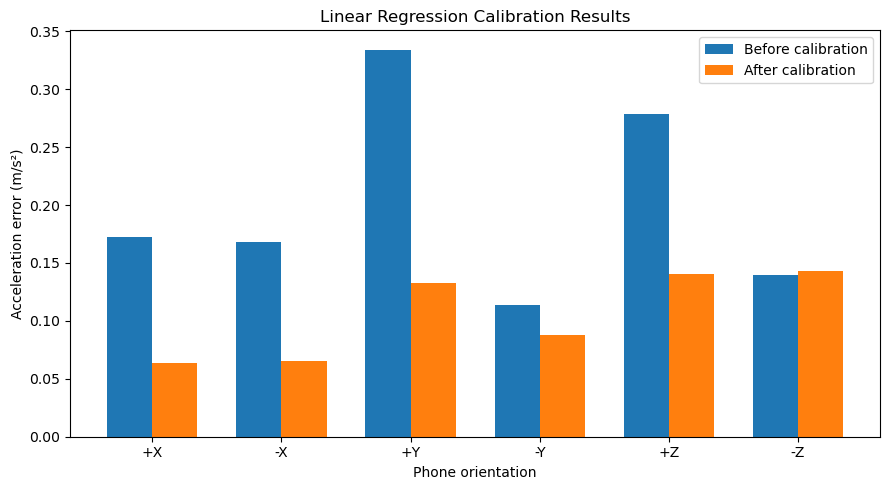

In [106]:
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["error_before_m_s2"],
    width,
    label="Before calibration"
)

plt.bar(
    x + width / 2,
    results_df["error_after_m_s2"],
    width,
    label="After calibration"
)

plt.xticks(x, results_df["pose"])
plt.xlabel("Phone orientation")
plt.ylabel("Acceleration error (m/s²)")
plt.title("Linear Regression Calibration Results")
plt.legend()
plt.tight_layout()

plt.savefig(
    "results/error_before_after.png",
    dpi=150
)

plt.show()
